<a href="https://colab.research.google.com/github/aviral911/DataScienceAndVisualization/blob/main/Matplotlib_Practice_Solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
np.random.seed(42)

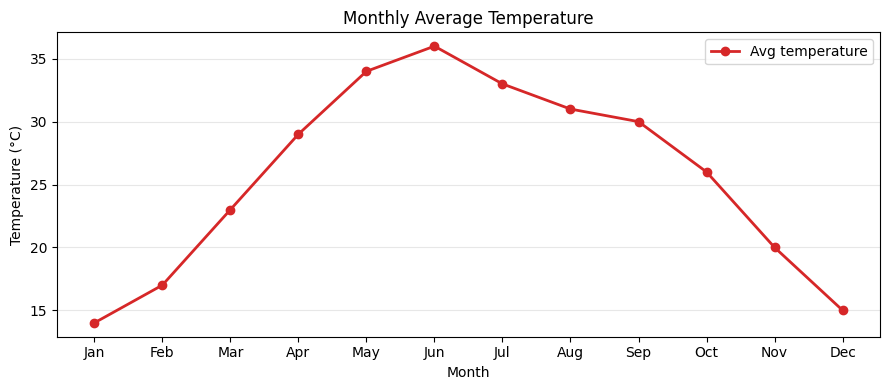

In [2]:
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
temp = [14, 17, 23, 29, 34, 36, 33, 31, 30, 26, 20, 15]   # deg C (illustrative, North India)
plt.figure(figsize=(9,4))
plt.plot(months, temp, marker="o", linewidth=2, color="tab:red", label="Avg temperature")
plt.title("Monthly Average Temperature"); plt.xlabel("Month"); plt.ylabel("Temperature (°C)")
plt.grid(axis="y", alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

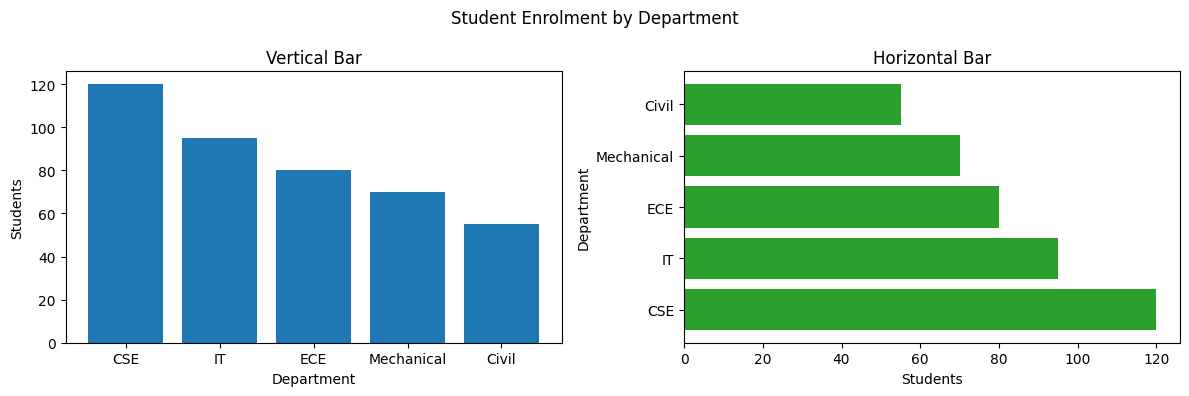

In [3]:
dept = ["CSE","IT","ECE","Mechanical","Civil"]
enrol = [120, 95, 80, 70, 55]
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].bar(dept, enrol, color="tab:blue"); ax[0].set_title("Vertical Bar")
ax[0].set_xlabel("Department"); ax[0].set_ylabel("Students")
ax[1].barh(dept, enrol, color="tab:green"); ax[1].set_title("Horizontal Bar")
ax[1].set_xlabel("Students"); ax[1].set_ylabel("Department")
fig.suptitle("Student Enrolment by Department"); fig.tight_layout(); plt.show()

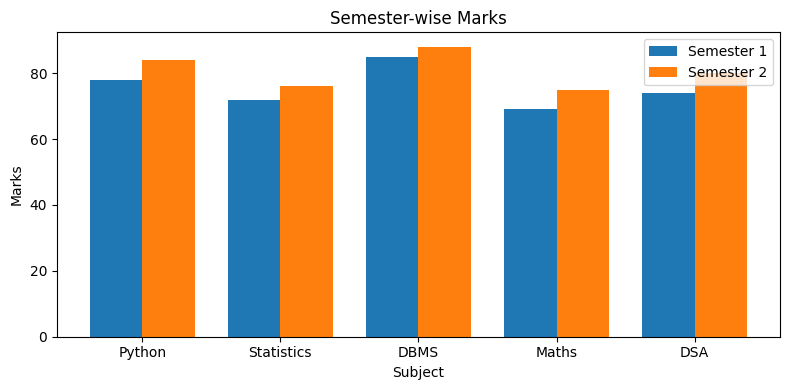

In [4]:
subjects = ["Python","Statistics","DBMS","Maths","DSA"]
sem1 = [78,72,85,69,74]; sem2 = [84,76,88,75,80]
x = np.arange(len(subjects)); w = .38
plt.figure(figsize=(8,4))
plt.bar(x-w/2, sem1, w, label="Semester 1"); plt.bar(x+w/2, sem2, w, label="Semester 2")
plt.xticks(x, subjects); plt.title("Semester-wise Marks"); plt.xlabel("Subject"); plt.ylabel("Marks")
plt.legend(); plt.tight_layout(); plt.show()

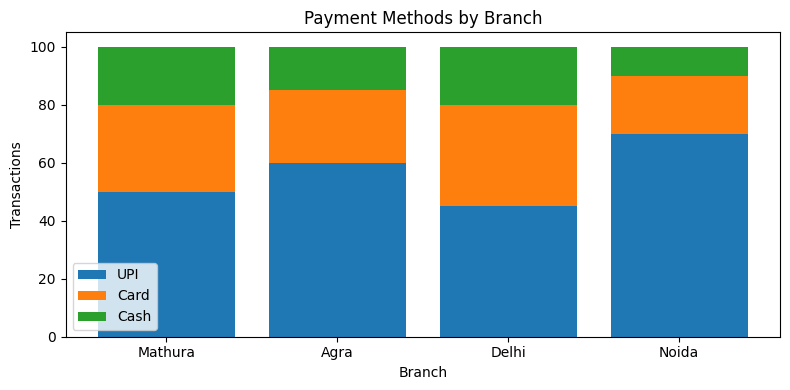

In [5]:
branches = ["Mathura","Agra","Delhi","Noida"]
upi = np.array([50,60,45,70]); card = np.array([30,25,35,20]); cash = np.array([20,15,20,10])
plt.figure(figsize=(8,4))
plt.bar(branches, upi, label="UPI")
plt.bar(branches, card, bottom=upi, label="Card")
plt.bar(branches, cash, bottom=upi+card, label="Cash")
plt.title("Payment Methods by Branch"); plt.xlabel("Branch"); plt.ylabel("Transactions")
plt.legend(); plt.tight_layout(); plt.show()

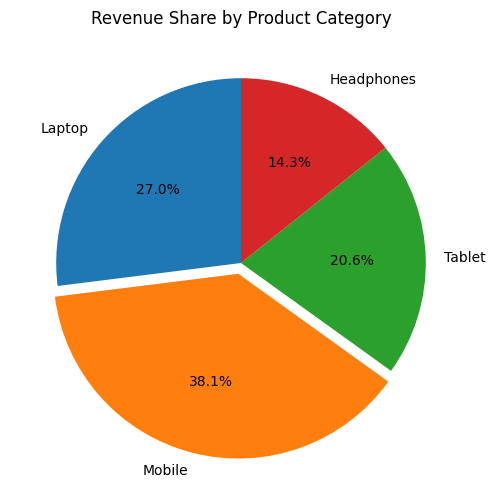

In [6]:
cats = ["Laptop","Mobile","Tablet","Headphones"]
rev = [85000,120000,65000,45000]
plt.figure(figsize=(6,6))
plt.pie(rev, labels=cats, autopct="%1.1f%%", startangle=90, explode=[0,.06,0,0])
plt.title("Revenue Share by Product Category"); plt.show()

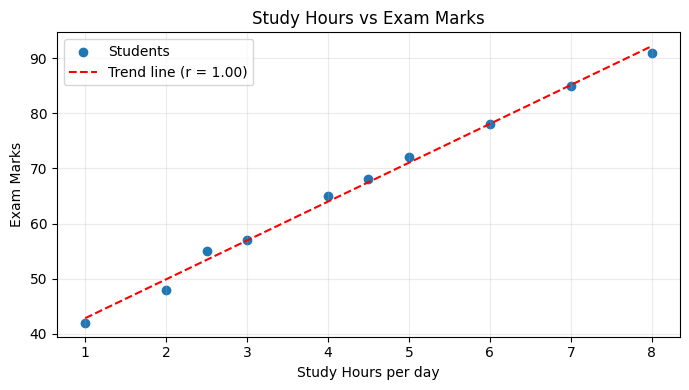

Correlation r = 0.998; slope = 7.0 marks per extra hour


In [7]:
hours = np.array([1,2,2.5,3,4,4.5,5,6,7,8])
marks = np.array([42,48,55,57,65,68,72,78,85,91])
r = np.corrcoef(hours, marks)[0,1]
m, b = np.polyfit(hours, marks, 1)
plt.figure(figsize=(7,4))
plt.scatter(hours, marks, label="Students")
plt.plot(hours, m*hours+b, "r--", label=f"Trend line (r = {r:.2f})")
plt.title("Study Hours vs Exam Marks"); plt.xlabel("Study Hours per day"); plt.ylabel("Exam Marks")
plt.grid(alpha=.25); plt.legend(); plt.tight_layout(); plt.show()
print(f"Correlation r = {r:.3f}; slope = {m:.1f} marks per extra hour")

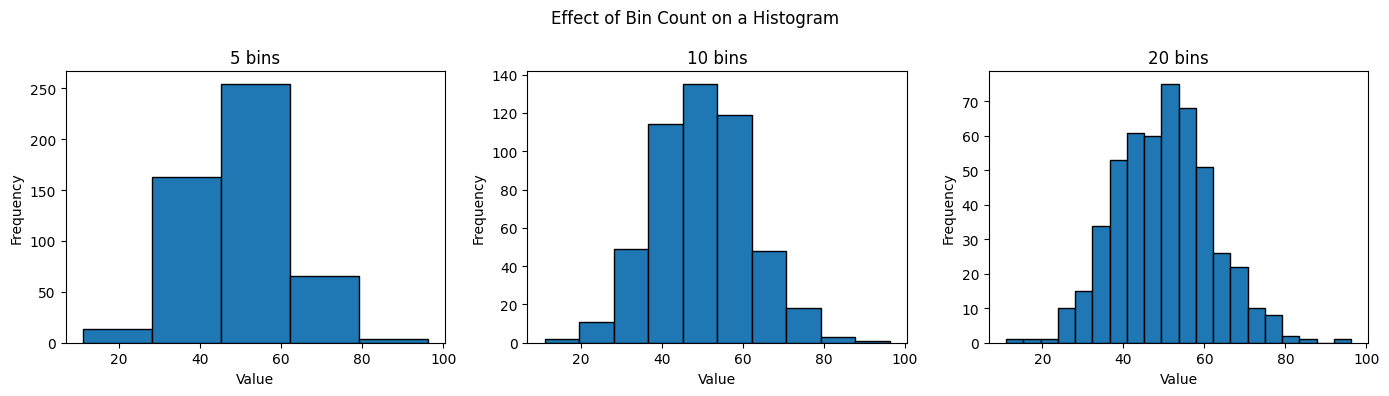

In [8]:
data = np.random.normal(50, 12, 500)
fig, ax = plt.subplots(1, 3, figsize=(14,4), sharey=False)
for a, bins in zip(ax, [5,10,20]):
    a.hist(data, bins=bins, edgecolor="black"); a.set_title(f"{bins} bins")
    a.set_xlabel("Value"); a.set_ylabel("Frequency")
fig.suptitle("Effect of Bin Count on a Histogram"); fig.tight_layout(); plt.show()

**Takeaway:** 5 bins over-smooth (hide the bell shape detail), 20 bins start showing noise, and ~10 bins give the best balance for 500 points.

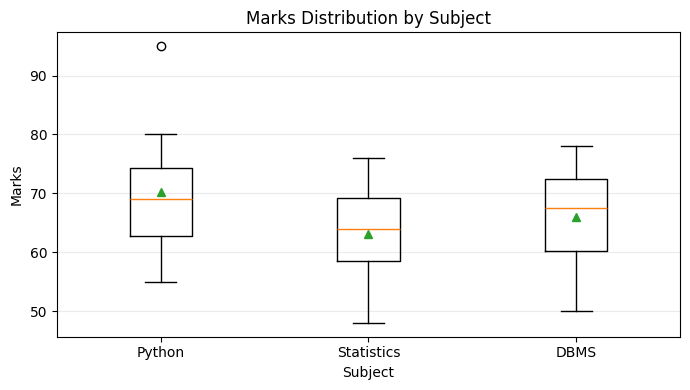

Python      median=69.0  IQR=11.5  range=40
Statistics  median=64.0  IQR=10.8  range=28
DBMS        median=67.5  IQR=12.2  range=28


In [9]:
python = [55,60,62,65,68,70,72,75,80,95]
stats  = [48,52,58,60,63,65,67,70,72,76]
dbms   = [50,55,59,64,66,69,71,73,75,78]
plt.figure(figsize=(7,4))
plt.boxplot([python, stats, dbms], tick_labels=["Python","Statistics","DBMS"], showmeans=True)
plt.title("Marks Distribution by Subject"); plt.xlabel("Subject"); plt.ylabel("Marks")
plt.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()
for n, d in [("Python",python),("Statistics",stats),("DBMS",dbms)]:
    q1,q3 = np.percentile(d,[25,75]); print(f"{n:<11} median={np.median(d):.1f}  IQR={q3-q1:.1f}  range={max(d)-min(d)}")

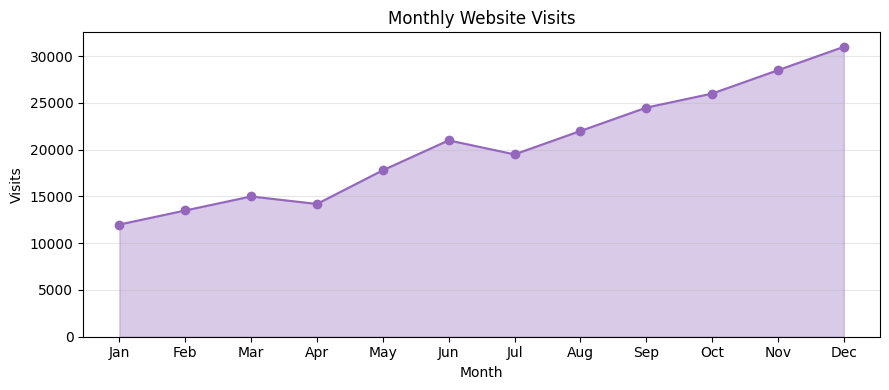

In [10]:
mon = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
visits = [12000,13500,15000,14200,17800,21000,19500,22000,24500,26000,28500,31000]
plt.figure(figsize=(9,4))
plt.fill_between(mon, visits, alpha=.35, color="tab:purple")
plt.plot(mon, visits, marker="o", color="tab:purple")
plt.title("Monthly Website Visits"); plt.xlabel("Month"); plt.ylabel("Visits")
plt.ylim(0); plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

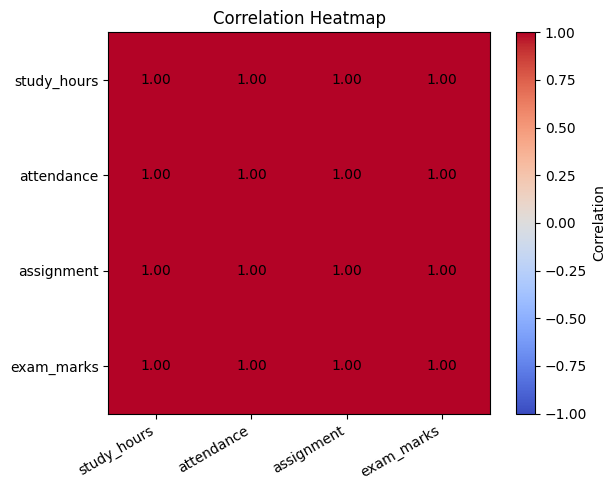

In [11]:
df = pd.DataFrame({
    "study_hours":[1,2,3,4,5,6,7,8],
    "attendance":[60,65,70,72,78,85,90,95],
    "assignment":[45,50,58,60,68,75,82,90],
    "exam_marks":[42,48,55,60,68,76,84,92]})
corr = df.corr()
plt.figure(figsize=(6.5,5))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, label="Correlation")
plt.xticks(range(4), corr.columns, rotation=30, ha="right"); plt.yticks(range(4), corr.index)
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center")
plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()

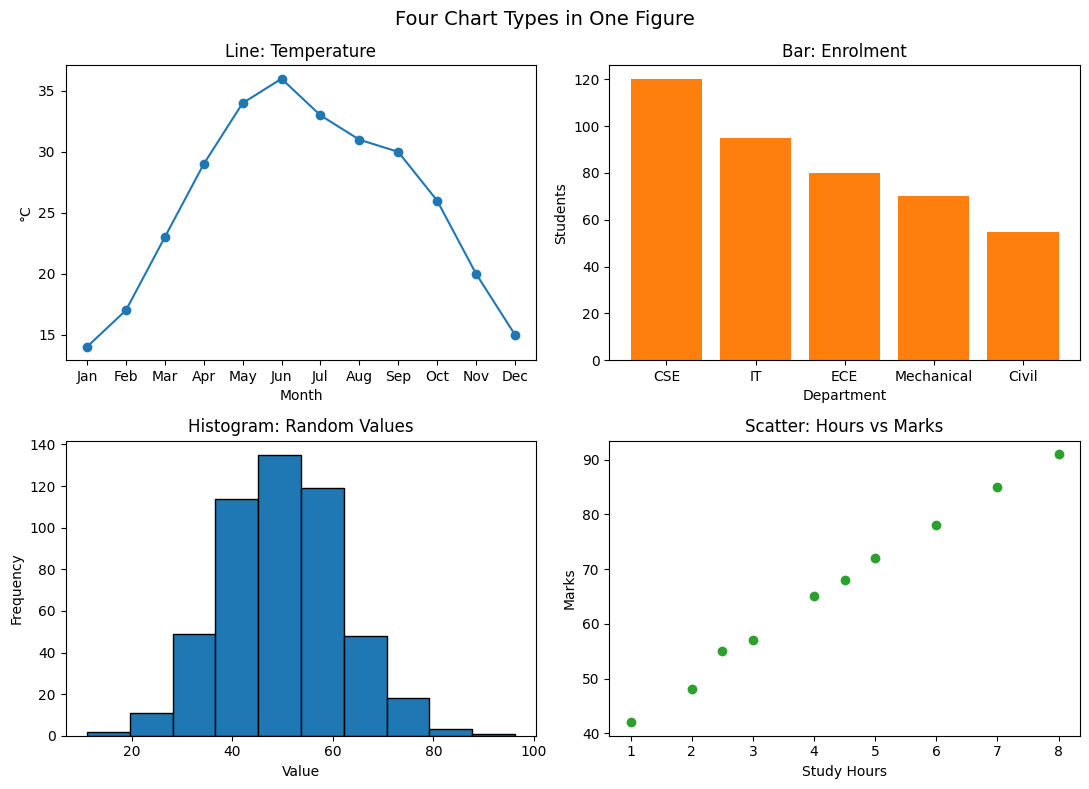

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11,8))
axes[0,0].plot(months, temp, marker="o"); axes[0,0].set_title("Line: Temperature")
axes[0,0].set_xlabel("Month"); axes[0,0].set_ylabel("°C")
axes[0,1].bar(dept, enrol, color="tab:orange"); axes[0,1].set_title("Bar: Enrolment")
axes[0,1].set_xlabel("Department"); axes[0,1].set_ylabel("Students")
axes[1,0].hist(data, bins=10, edgecolor="black"); axes[1,0].set_title("Histogram: Random Values")
axes[1,0].set_xlabel("Value"); axes[1,0].set_ylabel("Frequency")
axes[1,1].scatter(hours, marks, color="tab:green"); axes[1,1].set_title("Scatter: Hours vs Marks")
axes[1,1].set_xlabel("Study Hours"); axes[1,1].set_ylabel("Marks")
fig.suptitle("Four Chart Types in One Figure", fontsize=14); fig.tight_layout(); plt.show()

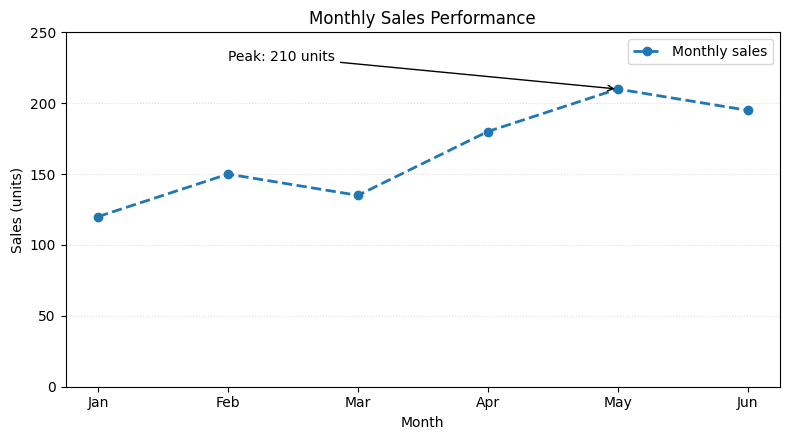

Saved monthly_sales.png


In [13]:
sales_m = ["Jan","Feb","Mar","Apr","May","Jun"]; sales = [120,150,135,180,210,195]
plt.figure(figsize=(8,4.5))
plt.plot(sales_m, sales, marker="o", linestyle="--", linewidth=2, label="Monthly sales")
plt.title("Monthly Sales Performance"); plt.xlabel("Month"); plt.ylabel("Sales (units)")
plt.ylim(0,250); plt.grid(axis="y", linestyle=":", alpha=.4)
plt.annotate("Peak: 210 units", xy=("May",210), xytext=("Feb",230), arrowprops={"arrowstyle":"->"})
plt.legend(); plt.tight_layout()
plt.savefig("monthly_sales.png", dpi=200, bbox_inches="tight"); plt.show()
print("Saved monthly_sales.png")